# Molecular docking

This is the main protocol of Jupyter Dock.

## Content of this notebook

1. Feching system and cleanup
2. Protein and ligand sanitization
3. System Visualization 
4. Docking with AutoDock Vina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - PDBQT results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map
5. Docking with Smina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - 3D visualization of docking results
    - 2D interaction table and map
6. Docking with LeDock
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - DOK results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map

In [2]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf

import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [3]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [4]:
cmd.fetch(code='5IKQ',type='pdb1')
cmd.select(name='Prot',selection='polymer.protein')
cmd.save(filename='5IKQ_clean.pdb',format='pdb',selection='Prot',state=1)

# 5IKQ's real bound inhibitor is meclofenamic acid, ligand code JMS (chain A
# copy only -- COX-2 is a homodimer, chain B has a second copy we don't
# need). state=1 pins this to a single biological-assembly copy: type='pdb1'
# can otherwise store multiple symmetry-related copies as separate PyMOL
# "states" under the same object/chain label, which would silently get
# written into the mol2 file together and inflate the docking box (verified:
# this caused a 75x75x99 A box before this fix).
cmd.select(name='NativeLig', selection='resn JMS and chain A')
_natlig_model = cmd.get_model('NativeLig', state=1)
_natlig_resns = sorted(set(a.resn for a in _natlig_model.atom))
print("Native ligand residue(s) found:", _natlig_resns, "| atom count:", len(_natlig_model.atom))
cmd.save(filename='5IKQ_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')

# Our actual compound of interest: Rosmarinic_acid, built from SMILES
# (PubChem CID 5281792) since it has no experimental crystal/mol2 structure.
from rdkit import Chem
from rdkit.Chem import AllChem
from rdkit.Chem.rdmolfiles import MolToPDBBlock
from openbabel import pybel

smiles = "C1=CC(=C(C=C1CC(C(=O)O)OC(=O)C=CC2=CC(=C(C=C2)O)O)O)O"
_m = Chem.MolFromSmiles(smiles)
_m = Chem.AddHs(_m)
AllChem.EmbedMolecule(_m, randomSeed=42, useRandomCoords=True)
AllChem.UFFOptimizeMolecule(_m)
with open('_Rosmarinic_acid.pdb', 'w') as f:
    f.write(MolToPDBBlock(_m))

_pmol = [x for x in pybel.readfile(filename='_Rosmarinic_acid.pdb', format='pdb')][0]
_out = pybel.Outputfile(filename='5IKQ_lig.mol2', format='mol2', overwrite=True)
_out.write(_pmol)
_out.close()
os.remove('_Rosmarinic_acid.pdb')


Native ligand residue(s) found: ['JMS'] | atom count: 29


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'5IKQ_clean.pdb'}

os.rename('pro.pdb','5IKQ_clean_H.pdb') # Output from lepro is pro.pdb, this line will change the name to '5IKQ_clean_H.pdb'


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='5IKQ_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='5IKQ_clean_H.pdb')
```

### 2.2. Ligand sanitization

Due to the variability of ligands and formats, ligand sanitization and preparation can be one of the most difficult tasks to complete. Setting protonation states for a ligand, for example, can be difficult. It is highly recommended that the user knows and understands the proper states for his/her ligand(s) when using Jupyter Dock or any other molecular docking approach.

In this example, after splitting the ligand and protein after fetching with pymol, the ligand has sanitization problems **(sanitize=False in Chem.MolFromMol2File)**

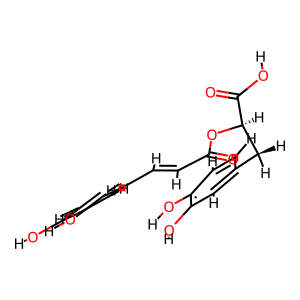

In [7]:
m=Chem.MolFromMol2File('5IKQ_lig.mol2',sanitize=False)
Draw.MolToImage(m)

>**Hint:** One solution for simple sanitization problems is to use OpenBAbel to convert the molecule and add the necessary hydrogens for molecular docking (Pybel). The definitions for carrying out molecules in OpenBabel differ from those in RDKIt. As a result, OpenBabel is capable of handling the conversion.

In [8]:
mol= [m for m in pybel.readfile(filename='5IKQ_lig.mol2',format='mol2')][0]
mol.addh()
out=pybel.Outputfile(filename='5IKQ_lig_H.mol2',format='mol2',overwrite=True)
out.write(mol)
out.close()

The end result of ligand sanitization is a new molecule that RDKit can display without having to use the sanitization parameter. Furthermore, the output structure for this example corresponds exactly to the one reported in the PDB database (PDB 5IKQ)

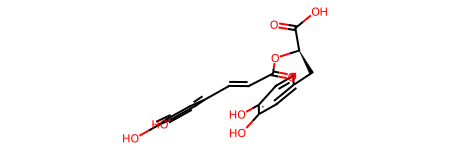

In [9]:
m=Chem.MolFromMol2File('5IKQ_lig_H.mol2')
m

## 3. System Visualization

A cool feature of Jupyter Dock is the posibility of visualize ligand-protein complexes and docking results into the notebbok. All this thanks to the powerful py3Dmol. 

Now the protein and ligand have been sanitized it would be recomended to vissualize the ligand-protein reference system.

In [10]:
view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open('5IKQ_clean_H.pdb','r').read(),format='pdb')
Prot=view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW,{'opacity':0.6,'color':'white'})


view.addModel(open('5IKQ_lig_H.mol2','r').read(),format='mol2')
ref_m = view.getModel()
ref_m.setStyle({},{'stick':{'colorscheme':'greenCarbon','radius':0.2}})

view.zoomTo()
view.show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [11]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [12]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'5IKQ_clean_H.pdb'} -o {'5IKQ_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment" (a known AutoDockTools/ADFRsuite fragility), use this fallback:
#
# import subprocess
# r = subprocess.run(["obabel", "5IKQ_clean_H.pdb", "-O", "5IKQ_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)


set verbose to  True
set receptor_filename to  5IKQ_clean_H.pdb
set outputfilename to  5IKQ_clean_H.pdbqt
read  5IKQ_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  5IKQ_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None


### 4.2. Ligand preparation

As previously discussed, one of the major challenges for proper docking experimentation is ligand preparation.

>**Hint:** The hydroges in this example were set during the ligand sanitization step (section 2.2). As a result, the ligand will be prepared as is. Furthermore, before running the docking, it is highly recommended to inspect the ligand(s) after preparation to ensure proper structure and molecule features.

#### Method 1: AutoDock Tools prepare_ligand

In [13]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand" #Launch this cell to see parameters


prepare_ligand4: ligand filename must be specified.
Usage: prepare_ligand4.py -l filename

    Description of command...
         -l     ligand_filename (.pdb or .mol2 or .pdbq format)
    Optional parameters:
        [-v]    verbose output
        [-o pdbqt_filename] (default output filename is ligand_filename_stem + .pdbqt)
        [-d]    dictionary to write types list and number of active torsions 
        [-A]    type(s) of repairs to make:
		 bonds_hydrogens, bonds, hydrogens (default is to do no repairs)
        [-C]    do not add charges (default is to add gasteiger charges)
        [-p]    preserve input charges on an atom type, eg -p Zn
               (default is not to preserve charges on any specific atom type)
        [-U]    cleanup type:
		 nphs_lps, nphs, lps, '' (default is 'nphs_lps') 
        [-B]    type(s) of bonds to allow to rotate 
               (default sets 'backbone' rotatable and 'amide' + 'guanidinium' non-rotatable)
        [-R]    index for root
        

In [14]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand" -v -l {'5IKQ_lig_H.mol2'} -o {'5IKQ_lig_H.pdbqt'}


set verbose to  True
set ligand_filename to  5IKQ_lig_H.mol2
set outputfilename to  5IKQ_lig_H.pdbqt
read  5IKQ_lig_H.mol2
setting up LPO with mode= automatic and outputfilename=  5IKQ_lig_H.pdbqt
and check_for_fragments= False
and bonds_to_inactivate= 
returning  0
No change in atomic coordinates


#### Method 2: Meeko

This is the preferred method out of AutoDock Tools. Apart from ligand preparation, Meeko provides tools for other docking aspects that the AutoDock Tools software suite does not cover. Hydrated docking and macrocycles are two examples. More about Meeko https://pypi.org/project/meeko/

>**Info**  To run Meeko change the next cell type from "Markdown" to "Code".

```
mol = obutils.load_molecule_from_file('5IKQ_lig_H.mol2')

preparator = MoleculePreparation(merge_hydrogens=True,hydrate=False)
preparator.prepare(mol)

preparator.write_pdbqt_file('5IKQ_lig_H.pdbqt')
```

#### Method 3: Pybel

OpenBabel (pybel) can handle a variety of file formats and conversions between them. As a result, any chemical format file can be converted directly to PDBQT. Nonetheless, pybel may encounter issues if the source file format contains errors. 

>**Info**  To run Pybel change the next cell type from "Markdown" to "Code".

```
ligand = [m for m in pybel.readfile(filename='5IKQ_lig_H.mol2',format='mol2')][0]
out=pybel.Outputfile(filename='5IKQ_lig_H.pdbqt',format='pdbqt',overwrite=True)
out.write(ligand)
out.close()
```

### 4.3. Box definition

This is possibly the most important feature of Jupyter Dock. Making a docking box without the use of a visualizer or any other additional tools. As a result, AutoDock Vina (and LeDock) can now be run entirely in a Jupyter notebook.

Mengwu Xiao and his clever Pymol plug-in ["GetBox"](https://github.com/MengwuXiao/GetBox-PyMOL-Plugin) inspired the box definition in Jupyter Dock. 

Jupyter Dock makes use of Mengwu Xiao Pymol implementation, but this time through the Pymol API.

>**Warning:** The function **_get_box()_** is built into the Pymol API. As a result, in order to compute the docking box, the docking system files must be initialized using Pymol.

>**Hint:** The integration of **_get_box()_** as Pymol integration allows the definition of amazing boxes based on Pymol's powerful selection tools. A ligand, a residue, a set of residues, atom(s), pseudoatom(s), and any custom selection valid within the [Pymol selection algebra](https://pymolwiki.org/index.php/Selection_Algebra) can be used to set the box.  

**_get_box( params )_**

params:

   - **selection**: _str , pymol_selection_; The selection for docking box, can be atom, resn, resid, or any other pymol selection
   
   - **extending**: _float_; value to extend the boundaries of the selection
   
   - **software**: _str , 'vina','ledock', 'both'_ ; Depending on selected software the funtion will provide the box coordinates in vina, ledock, or both formats

In [15]:
cmd.load(filename='5IKQ_clean_H.pdb',format='pdb',object='prot',state=1)
cmd.load(filename='5IKQ_native_lig.mol2',format='mol2',object='natlig',state=1)

center, size= getbox(selection='natlig',extending=5.0,software='vina')

cmd.delete('all')

print(center,'\n',size)


{'center_x': 22.227499961853027, 'center_y': 51.4325008392334, 'center_z': 17.643500328063965} 
 {'size_x': 17.072999954223633, 'size_y': 18.78499984741211, 'size_z': 15.440999984741211}


### 4.4. Docking 

AutoDock Vina 1.2.0, which was recently released, now allows AutoDock Vina to be executed using Python Bindings. Jupyter Dock takes advantage of this feature to make the docking protocol run entirely within a Jupyter notebook.

In [ ]:
v = Vina(sf_name='vina')

v.set_receptor('5IKQ_clean_H.pdbqt')

v.set_ligand_from_file('5IKQ_lig_H.pdbqt')

v.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']], 
                    box_size=[size['size_x'], size['size_y'], size['size_z']])

# Dock the ligand (global search -- doesn't require the starting pose to
# already be inside the box, unlike score()/optimize(), which is why those
# are skipped here)
v.dock(exhaustiveness=10, n_poses=10)
v.write_poses('5IKQ_lig_vina_out.pdbqt', n_poses=10, overwrite=True)

energies = v.energies(n_poses=10)
print("Vina pose energies (kcal/mol):")
for i, e in enumerate(energies):
    print(f"  Pose {i+1}: {e[0]:.3f}")


### 4.5. PDBQT results file conversion to SDF

Because of the unique characteristics of the PDBQT format, it may be difficult to visualize the results or perform other analyses after docking. As a result, Jupyter Dock automatically converts the PDFBQT format to the more common SDF format. The file conversion preserves the chemical properties of the compounds after they have been sanitized and prepared. Furthermore, the "Pose" and "Score" information is saved as a molecule attribute. Such data can be accessed directly in the file or via Pybel or RDKit.

**_pdbqt_to_sdf ( params )_**

params:

- **pdbqt_file**: _str or path-like string_ ; pdbqt file to be converted, extension must be pdbqt
- **output**: _str or path-like string_  ; output sdf file, extension must be sdf

In [ ]:
pdbqt_to_sdf(pdbqt_file='5IKQ_lig_vina_out.pdbqt',output='5IKQ_lig_vina_out.sdf')

### 4.6. 3D visualization of docking results (AutoDock Vina)

As with the system visualization (section 3), the docking results can be inspected and compared to the reference structure (if exist). The ligand's "Pose" and "Score" information will also be displayed to show how acces to this molecule's attributes.

In [ ]:
view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open('5IKQ_clean_H.pdb','r').read(),format='pdb')
Prot=view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW,{'opacity':0.6,'color':'white'})


view.addModel(open('5IKQ_lig_H.mol2','r').read(),format='mol2')
ref_m = view.getModel()
ref_m.setStyle({},{'stick':{'colorscheme':'magentaCarbon','radius':0.2}})


results=Chem.SDMolSupplier('5IKQ_lig_vina_out.sdf')

p=Chem.MolToMolBlock(results[0],False)

print('Reference: Magenta | Vina Pose: Cyan')
print ('Pose: {} | Score: {}'.format(results[0].GetProp('Pose'),results[0].GetProp('Score')))

view.addModel(p,'mol')
x = view.getModel()
x.setStyle({},{'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()

### 4.7. 2D interaction table and map

Inspecting the molecular interactions is one of the most common analyses performed by a computational scientist following a docking experiment. As a result, Jupyter Dock uses ProLif to create a table of ligand-protein molecular interactions as well as the corresponding 2D map.

>**Info:** ProLif uses RDKit and MDAnalysis to map the molecular interaction between a ligand and a protein. As a result, some protein preparations, including the use of LePro, can result in errors that impede analysis. Jupyter Dock's _**fix protein()_** function can be used to avoid such errors and provide a suitable protein structure for the analysis.

In [ ]:
fix_protein(filename='5IKQ_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='5IKQ_clean_H_fix.pdb')

In [ ]:
# load protein
prot = mda.Universe("5IKQ_clean_H_fix.pdb")
prot = plf.Molecule.from_mda(prot)
prot.n_residues

# load ligands
lig_suppl = list(plf.sdf_supplier('5IKQ_lig_vina_out.sdf'))
# generate fingerprint
fp = plf.Fingerprint()
fp.run_from_iterable(lig_suppl, prot, n_jobs=1)
results_df = fp.to_dataframe()
results_df


In [ ]:
net = fp.plot_lignetwork(lig_suppl[0], kind="frame", frame=0, rotation=270)
net.display()


## 5. Docking with Smina

Despite the presence of Python bindings in AutoDock Vina 1.2.0, other tools that incorporate AutoDock Vina allow for cool features such as custom score functions (smina), fast execution (qvina), and the use of wider boxes (qvina-w). Jupyter Dock can run such binaries in a notebook, giving users more options.

Smina is a fork of AutoDock Vina that is customized to better support scoring function development and high-performance energy minimization. Smina is maintained by David Koes at the University of Pittsburgh and is not directly affiliated with the AutoDock project.

>**Info:** The following cell contains an example of using Smina to run the current docking example. However, the executable files for qvina and qvina-w are available in the Jupyter Dock repo's bin directory. As a result, the user can use such a tool by adding the necessary cells or replacing the current docking engine.

### 5.1. Receptor preparation

Despite the fact that Smina is a modified version of AutoDock Vina, the input file for a receptor in Smina can be either a PDBQT file or a PDB file with explicit hydrogens in all residues. At this point, we can make use of the file sanitization steps as well as a protein structure from Jupyter Dock's _**fix_protein()**_ function.

### 5.2. Ligand preparation

In Smina, we can use any OpenBabel format for ligand input and docking results, just like we can for receptor preparation. As a result, after sanitization, we can use the ligand MOL2 file here. 

### 5.3. Docking box definition

This step can be completed in the same manner as the AutoDock Vina box definition.

### 5.4. Docking

Jupyter Dock comes with the smina executable for Linux and Mac OS. By running the binary file, the parameters can be accessed.

In [ ]:
!../../bin/smina #Lauch this cell to see parameters

In [ ]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/smina" -r {'5IKQ_clean_H.pdb'} -l {'5IKQ_lig_H.mol2'} -o {'5IKQ_lig_smina_out.sdf'} --center_x {center['center_x']} --center_y {center['center_y']} --center_z {center['center_z']} --size_x {size['size_x']} --size_y {size['size_y']} --size_z {size['size_z']} --exhaustiveness 8 --num_modes 10


### 5.6. 3D visualization of docking results

As with the system visualization (section 3), the docking results can be inspected and compared to the reference structure (if one exists). Smina saves the "minimizedAffinity" information corresponding to the docking score as the molecule's attribute.

In [ ]:
view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open('5IKQ_clean_H.pdb','r').read(),format='pdb')
Prot=view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW,{'opacity':0.6,'color':'white'})


view.addModel(open('5IKQ_lig_H.mol2','r').read(),format='mol2')
ref_m = view.getModel()
ref_m.setStyle({},{'stick':{'colorscheme':'magentaCarbon','radius':0.2}})


results=Chem.SDMolSupplier('5IKQ_lig_smina_out.sdf')

p=Chem.MolToMolBlock(results[0],False)

print('Reference: Magenta | Smina Pose: Cyan')
print ('Score: {}'.format(results[0].GetProp('minimizedAffinity')))

view.addModel(p,'mol')
x = view.getModel()
x.setStyle({},{'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()

### 5.7. 2D interaction table and map

Inspecting the molecular interactions is one of the most common analyses performed by a computational scientist following a docking experiment. As a result, Jupyter Dock uses ProLif to create a table of ligand-protein molecular interactions as well as the corresponding 2D map.

>**Info:** ProLif uses RDKit and MDAnalysis to map the molecular interaction between a ligand and a protein. As a result, some protein preparations, including the use of LePro, can result in errors that impede analysis. Jupyter Dock's _**fix protein()_** function can be used to avoid such errors and provide a suitable protein structure for the analysis.

In [ ]:
# load protein
prot = mda.Universe("5IKQ_clean_H_fix.pdb")
prot = plf.Molecule.from_mda(prot)
prot.n_residues

# load ligands
lig_suppl = list(plf.sdf_supplier('5IKQ_lig_smina_out.sdf'))
# generate fingerprint
fp = plf.Fingerprint()
fp.run_from_iterable(lig_suppl, prot, n_jobs=1)
results_df = fp.to_dataframe()
results_df


In [ ]:
net = fp.plot_lignetwork(lig_suppl[0], kind="frame", frame=0, rotation=270)
net.display()


## 6. Docking with LeDock

LeDock is designed for fast and accurate flexible docking of small molecules into a protein. It achieves a pose-prediction accuracy of greater than 90% on the Astex diversity set and takes about 3 seconds per run for a drug-like molecule. It has led to the discovery of novel kinase inhibitors and bromodomain antagonists from high-throughput virtual screening campaigns. It directly uses SYBYL Mol2 format as input for small molecules.

### 6.1. Receptor preparation

In LeDock, the input file for a receptor is a PDB file with explicit hydrogens in all residues. LePro was created as a tool for preparing protein structures for docking with LeDock. Thus, at this stage, we can use the file ater sanitization steps as well as a protein structure from Jupyter Dock's _**fix_protein()**_ function.

### 6.2. Ligand preparation

As previously stated, the input format for ligand in LeDock is MOL2. Similarly to the receptor preparation, we can use the ligand directly after sanitization. 

### 6.3. Docking box definition

This step can be completed in the same manner as the AutoDock Vina box definition. To obtain the identical box from AutoDock Vina docking but in LeDock format, the user only needs to change the parameter "software" from "vina" to "ledock." 

>**Info:** The implementation of the _**get_box()**_ function allows for the easy replication of binding sites between AutoDock Vina and LeDock, with the goal of replicating and comparing results between both programs.

In [ ]:
cmd.load(filename='5IKQ_clean_H.pdb',format='pdb',object='prot',state=1)
cmd.load(filename='5IKQ_native_lig.mol2',format='mol2',object='natlig',state=1)

X,Y,Z= getbox(selection='natlig',extending=5.0,software='ledock')
cmd.delete('all')

print(X,'\n',Y,'\n',Z)


### 6.4. Docking

To run LeDock, a configuration (commonly known as dock.in) file containing all docking parameters as well as information about the receptor and ligand(s) to dock is required. Jupyter Dock uses the function _**generate ledock file()**_ to generate the configuration file automatically. After configuring the parameters, the user will receive a configuration file as well as a file containing a list of ligand(s) to dock (commonly named ligand.list). After this, docking would be as simple as launching the LeDock executable and the configuration file as parameter.

**_generate_ledock_file( params )_**

params:

- **receptor**: _str or path-like string_ ; protein file for docking including hydrogens, format must be pdb 
- **x**: _2 element list of floats [ float , float ]_; Xmin and Xmax coordinates of docking box
- **y**:  _2 element list of floats [ float , float ]_; Ymin and Ymax coordinates of docking box
- **z**:  _2 element list of floats [ float , float ]_; Zmin and Zmax coordinates of docking box
- **n_poses**: _float_ ; n_of poses to retrieve from docking 
- **rmsd**: _float_ ; minimum RMSD diference between docking poses 
- **l_list**: _list of n strings or path-like strings [ lig1, lig2, lig3 ... ] ; list of ligands or ligands paths to dock 
- **l_list_outfile**: _str or path-like string_ ; filename to save the ligand list, needed for ledock to locate ligands
- **out**: _str or path-like string_ ; outfile to save docking paramemeters, needed to launch the docking

In [ ]:
generate_ledock_file(receptor='5IKQ_clean_H.pdb',x=[X['minX'],X['maxX']],
                     y=[Y['minY'],Y['maxY']],
                     z=[Z['minZ'],Z['maxZ']],
                     n_poses=10,
                     rmsd=1.0,
                     l_list='5IKQ_lig_H.mol2', 
                     l_list_outfile='ledock_ligand.list',
                     out='dock.in')

In [ ]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/ledock_linux_x86" #Launch this cell to see parameters


In [ ]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/ledock_linux_x86" {'dock.in'}


### 6.5. DOK results file conversion to SDF

The end result of LeDock is a file with the dok extension that contains the docking properties in the same way that a pdb file does. Nonetheless, the dok file is not a widely used format for representing chemical structures. As a result, Jupyter Dock can convert dok files to the widely used sdf format. Jupyter Dock, like in the pdbqt to sdf conversion, will preserve the chemical features and save the "Pose" and "Score" results as molecule attributes.

**_dok_to_sdf ( params )_**

params:

   - **dok_file**: _str or path-like_ ; dok file from ledock docking

   - **output**: _str or path-like_ ; out file from ledock docking, extension must be sdf

In [ ]:
dok_to_sdf(dok_file='5IKQ_lig_H.dok',output='5IKQ_lig_ledock_out.sdf')

### 6.6. 3D visualization of docking results

As with the system visualization (section 3), the docking results can be inspected and compared to the reference structure (if exist). The ligand's "Pose" and "Score" information will also be displayed to show how acces to this molecule's attributes.

In [ ]:
view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open('5IKQ_clean_H.pdb','r').read(),format='pdb')
Prot=view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW,{'opacity':0.6,'color':'white'})


view.addModel(open('5IKQ_lig_H.mol2','r').read(),format='mol2')
ref_m = view.getModel()
ref_m.setStyle({},{'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results=Chem.SDMolSupplier('5IKQ_lig_ledock_out.sdf')


p=Chem.MolToMolBlock(results[0])

print('Reference: Magenta | LeDock Pose: Cyan')
print ('Pose: {} | Score: {}'.format(results[0].GetProp('Pose'),results[0].GetProp('Score')))

view.addModel(p,'mol')
x = view.getModel()
x.setStyle({},{'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()

### 6.7. 2D interaction table and map

Inspecting the molecular interactions is one of the most common analyses performed by a computational scientist following a docking experiment. As a result, Jupyter Dock uses ProLif to create a table of ligand-protein molecular interactions as well as the corresponding 2D map.

> **Info:** ProLif uses RDKit and MDAnalysis to map the molecular interaction between a ligand and a protein. As a result, some protein preparations, including the use of LePro, can result in errors that impede analysis. Jupyter Dock's _fix protein()_ function can be used to avoid such errors and provide a suitable protein structure for the analysis.

In [ ]:
# load protein
prot = mda.Universe("5IKQ_clean_H_fix.pdb",guess_bonds=True)
prot = plf.Molecule.from_mda(prot)
prot.n_residues

# load ligands
path = str('5IKQ_lig_ledock_out.sdf')
lig_suppl = list(plf.sdf_supplier(path))
# generate fingerprint
fp = plf.Fingerprint()
fp.run_from_iterable(lig_suppl, prot, n_jobs=1)
results_df = fp.to_dataframe()
results_df


In [ ]:
net = fp.plot_lignetwork(lig_suppl[0], kind="frame", frame=0, rotation=270)
net.display()


## 7. Screening PHYTO compounds (Lavandula_dentata) against COX-2

Reuses the receptor (`5IKQ_clean_H.pdb`/`.pdbqt`) and the docking box
(native ligand JMS, chain A, `state=1` -- Section 1) prepared above. Each
compound docked in its own cell with its own uniquely-named variables, seed
pinned at 42. Source: Dob et al. 2005 (Cherchel region, north-west Algiers).
SMILES verified against PubChem (formulas cross-checked with RDKit before
use): 1,8-Cineole (CID 2758), cis-Verbenol (CID 61126, non-stereo form),
p-Cymen-8-ol (CID 14529), Myrtenal (CID 61130, non-stereo form).

In [16]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "5IKQ_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "5IKQ_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "5IKQ_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand, `state=1`)

In [17]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': 22.227499961853027, 'center_y': 51.4325008392334, 'center_z': 17.643500328063965} 
 {'size_x': 17.072999954223633, 'size_y': 18.78499984741211, 'size_z': 15.440999984741211}


### 7.2. Dock **Cineole_1_8** against COX-2 (5IKQ)

In [18]:
# ---- Cineole_1_8 (Lavandula_dentata, Dob et al. 2005) ----
smiles_Cineole_1_8 = "CC1(C2CCC(O1)(CC2)C)C"
lig_pdbqt_Cineole_1_8 = prepare_ligand_from_smiles("Cineole_1_8", smiles_Cineole_1_8)

v_Cineole_1_8 = Vina(sf_name='vina', seed=VINA_SEED)
v_Cineole_1_8.set_receptor(RECEPTOR_PDBQT)
v_Cineole_1_8.set_ligand_from_file(lig_pdbqt_Cineole_1_8)
v_Cineole_1_8.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Cineole_1_8.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Cineole_1_8 = os.path.join(DOCKING_DIR, "Cineole_1_8_5IKQ_vina_out.pdbqt")
v_Cineole_1_8.write_poses(vina_out_pdbqt_Cineole_1_8, n_poses=10, overwrite=True)

energies_Cineole_1_8 = v_Cineole_1_8.energies(n_poses=10)
best_score_Cineole_1_8 = round(float(energies_Cineole_1_8[0][0]), 3)

print("=== Cineole_1_8 ===")
print(f"Best Vina score: {best_score_Cineole_1_8} kcal/mol")
for i, e in enumerate(energies_Cineole_1_8):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Cineole_1_8 = vina_out_pdbqt_Cineole_1_8.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Cineole_1_8, output=vina_out_sdf_Cineole_1_8)


  Cineole_1_8: 20 conformers generated, lowest energy = 38.38 kcal/mol (conf 9)
=== Cineole_1_8 ===
Best Vina score: -5.738 kcal/mol
  Pose 1: -5.738
  Pose 2: -5.547
  Pose 3: -5.483
  Pose 4: -5.180
  Pose 5: -5.039
  Pose 6: -4.964
  Pose 7: -4.963
  Pose 8: -4.940
  Pose 9: -4.922
  Pose 10: -4.839
Computing Vina grid ... 

done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.3. Dock **cis_Verbenol** against COX-2 (5IKQ)

In [19]:
# ---- cis_Verbenol (Lavandula_dentata, Dob et al. 2005) ----
smiles_cis_Verbenol = "CC1=CC(C2CC1C2(C)C)O"
lig_pdbqt_cis_Verbenol = prepare_ligand_from_smiles("cis_Verbenol", smiles_cis_Verbenol)

v_cis_Verbenol = Vina(sf_name='vina', seed=VINA_SEED)
v_cis_Verbenol.set_receptor(RECEPTOR_PDBQT)
v_cis_Verbenol.set_ligand_from_file(lig_pdbqt_cis_Verbenol)
v_cis_Verbenol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_cis_Verbenol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_cis_Verbenol = os.path.join(DOCKING_DIR, "cis_Verbenol_5IKQ_vina_out.pdbqt")
v_cis_Verbenol.write_poses(vina_out_pdbqt_cis_Verbenol, n_poses=10, overwrite=True)

energies_cis_Verbenol = v_cis_Verbenol.energies(n_poses=10)
best_score_cis_Verbenol = round(float(energies_cis_Verbenol[0][0]), 3)

print("=== cis_Verbenol ===")
print(f"Best Vina score: {best_score_cis_Verbenol} kcal/mol")
for i, e in enumerate(energies_cis_Verbenol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_cis_Verbenol = vina_out_pdbqt_cis_Verbenol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_cis_Verbenol, output=vina_out_sdf_cis_Verbenol)


  cis_Verbenol: 20 conformers generated, lowest energy = 28.10 kcal/mol (conf 13)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.738          0          0
   2       -5.547     0.8689      3.308
   3       -5.483      1.379      2.704
   4        -5.18      1.506      3.046
   5       -5.039      1.328      1.942
   6       -4.964      1.587      3.197
   7       -4.963      1.319      3.301
   8        -4.94      1.752      3.763
   9       -4.922      1.914      3.963
  10       -4.839      1.497       3.55
Computing Vina grid ... === cis_Verbenol ===
Best Vina score: -5.696 kcal/mol
  Pose 1: -5.696
  Pose 2: -5.579
  Pose 3: -5.532
  Pose 4: -5.467
  Pose 5: -5.192
  Pose 6: -4.988
  Pose 7: -4.890
  Pose 8: -4.847
  Pose 9: -4.704
  Pose 10: -4.660


done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.4. Dock **p_Cymen_8_ol** against COX-2 (5IKQ)

In [20]:
# ---- p_Cymen_8_ol (Lavandula_dentata, Dob et al. 2005) ----
smiles_p_Cymen_8_ol = "CC1=CC=C(C=C1)C(C)(C)O"
lig_pdbqt_p_Cymen_8_ol = prepare_ligand_from_smiles("p_Cymen_8_ol", smiles_p_Cymen_8_ol)

v_p_Cymen_8_ol = Vina(sf_name='vina', seed=VINA_SEED)
v_p_Cymen_8_ol.set_receptor(RECEPTOR_PDBQT)
v_p_Cymen_8_ol.set_ligand_from_file(lig_pdbqt_p_Cymen_8_ol)
v_p_Cymen_8_ol.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_p_Cymen_8_ol.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_p_Cymen_8_ol = os.path.join(DOCKING_DIR, "p_Cymen_8_ol_5IKQ_vina_out.pdbqt")
v_p_Cymen_8_ol.write_poses(vina_out_pdbqt_p_Cymen_8_ol, n_poses=10, overwrite=True)

energies_p_Cymen_8_ol = v_p_Cymen_8_ol.energies(n_poses=10)
best_score_p_Cymen_8_ol = round(float(energies_p_Cymen_8_ol[0][0]), 3)

print("=== p_Cymen_8_ol ===")
print(f"Best Vina score: {best_score_p_Cymen_8_ol} kcal/mol")
for i, e in enumerate(energies_p_Cymen_8_ol):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_p_Cymen_8_ol = vina_out_pdbqt_p_Cymen_8_ol.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_p_Cymen_8_ol, output=vina_out_sdf_p_Cymen_8_ol)


  p_Cymen_8_ol: 20 conformers generated, lowest energy = 31.68 kcal/mol (conf 12)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -5.696          0          0
   2       -5.579      1.894      3.022
   3       -5.532      1.904      3.706
   4       -5.467      1.118      2.715
   5       -5.192      2.285      3.105
   6       -4.988      2.056      3.258
   7        -4.89      1.844      3.056
   8       -4.847      2.341      4.067
   9       -4.704      2.099      3.103
  10        -4.66      1.512      2.962
Computing Vina grid ... done.
=== p_Cymen_8_ol ===
Best Vina score: -6.687 kcal/mol
  Pose 1: -6.687
  Pose 2: -6.276
  Pose 3: -6.210
  Pose 4: -5.953
  Pose 5: -5.890
  Pose 6: -5.782
  Pose 7: -5.740
  Pose 8: -5.566
  Pose 9: -5.380
  Pose 10: -5.243


Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.5. Dock **Myrtenal** against COX-2 (5IKQ)

In [21]:
# ---- Myrtenal (Lavandula_dentata, Dob et al. 2005) ----
smiles_Myrtenal = "CC1(C)C2CC=C(C=O)C1C2"
lig_pdbqt_Myrtenal = prepare_ligand_from_smiles("Myrtenal", smiles_Myrtenal)

v_Myrtenal = Vina(sf_name='vina', seed=VINA_SEED)
v_Myrtenal.set_receptor(RECEPTOR_PDBQT)
v_Myrtenal.set_ligand_from_file(lig_pdbqt_Myrtenal)
v_Myrtenal.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Myrtenal.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Myrtenal = os.path.join(DOCKING_DIR, "Myrtenal_5IKQ_vina_out.pdbqt")
v_Myrtenal.write_poses(vina_out_pdbqt_Myrtenal, n_poses=10, overwrite=True)

energies_Myrtenal = v_Myrtenal.energies(n_poses=10)
best_score_Myrtenal = round(float(energies_Myrtenal[0][0]), 3)

print("=== Myrtenal ===")
print(f"Best Vina score: {best_score_Myrtenal} kcal/mol")
for i, e in enumerate(energies_Myrtenal):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Myrtenal = vina_out_pdbqt_Myrtenal.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Myrtenal, output=vina_out_sdf_Myrtenal)


  Myrtenal: 20 conformers generated, lowest energy = 41.27 kcal/mol (conf 6)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.687          0          0
   2       -6.276      2.168      4.095
   3        -6.21       1.89      4.339
   4       -5.953      2.348      3.318
   5        -5.89      1.892      4.679
   6       -5.782        2.9      5.062
   7        -5.74       3.22      4.371
   8       -5.566       2.23      4.603
   9        -5.38      2.175      2.812
  10       -5.243      2.559      5.539
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== Myrtenal ===
Best Vina score: -5.98 kcal/mol
  Pose 1: -5.980
  Pose 2: -5.962
  Pose 3: -5.912
  Pose 4: -5.543
  Pose 5: -5.521
  Pose 6: -5.388
  Pose 7: -5.252
 

### 7.6. Total docking results table -- Lavandula_dentata vs COX-2

In [22]:
docking_rows_dentata = [
    {"Compound": "Cineole_1_8",   "Target": "COX-2 (5IKQ)", "Best_Vina_Score_kcal_mol": best_score_Cineole_1_8},
    {"Compound": "cis_Verbenol",  "Target": "COX-2 (5IKQ)", "Best_Vina_Score_kcal_mol": best_score_cis_Verbenol},
    {"Compound": "p_Cymen_8_ol",  "Target": "COX-2 (5IKQ)", "Best_Vina_Score_kcal_mol": best_score_p_Cymen_8_ol},
    {"Compound": "Myrtenal",      "Target": "COX-2 (5IKQ)", "Best_Vina_Score_kcal_mol": best_score_Myrtenal},
]

docking_df_dentata = pd.DataFrame(docking_rows_dentata).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_dentata.to_csv(os.path.join(DOCKING_DIR, "lavandula_dentata_vs_COX2_vina.csv"), index=False)
docking_df_dentata


,Compound,Target,Best_Vina_Score_kcal_mol
0,p_Cymen_8_ol,COX-2 (5IKQ),-6.687
1,Myrtenal,COX-2 (5IKQ),-5.980
2,Cineole_1_8,COX-2 (5IKQ),-5.738
3,cis_Verbenol,COX-2 (5IKQ),-5.696


### 7.7. Figure -- docking score comparison, Lavandula_dentata vs COX-2

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#e85d04' if s == docking_df_dentata['Best_Vina_Score_kcal_mol'].min() else '#ffba08'
          for s in docking_df_dentata['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_dentata['Compound'], docking_df_dentata['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Lavandula dentata compounds vs. COX-2 (5IKQ)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_dentata['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')
plt.tight_layout()

fig_path_dentata = os.path.join(FIGURES_DIR, 'lavandula_dentata_vs_COX2_scores.png')
plt.savefig(fig_path_dentata, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_dentata)


### 7.8. ProLif interaction fingerprints -- Lavandula_dentata (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [1]:
prot_fp = mda.Universe("5IKQ_clean_H_fix.pdb")  # fix_protein() output, from Section 4.7 above
prot_fp = plf.Molecule.from_mda(prot_fp)


NameError: name 'mda' is not defined

In [ ]:
# ---- ProLif: Cineole_1_8 ----
lig_suppl_Cineole_1_8 = list(plf.sdf_supplier(vina_out_sdf_Cineole_1_8))
fp_Cineole_1_8 = plf.Fingerprint()
fp_Cineole_1_8.run_from_iterable(lig_suppl_Cineole_1_8, prot_fp, n_jobs=1)
results_df_Cineole_1_8 = fp_Cineole_1_8.to_dataframe()

print("=== Cineole_1_8 ===")
display(results_df_Cineole_1_8)

net_Cineole_1_8 = fp_Cineole_1_8.plot_lignetwork(lig_suppl_Cineole_1_8[0], kind="frame", frame=0, rotation=270)
net_png_Cineole_1_8 = os.path.join(FIGURES_DIR, "Cineole_1_8_5IKQ_2Dnetwork.png")
net_Cineole_1_8.save_png(net_png_Cineole_1_8)
print("Saved network figure:", net_png_Cineole_1_8)


In [ ]:
# ---- ProLif: cis_Verbenol ----
lig_suppl_cis_Verbenol = list(plf.sdf_supplier(vina_out_sdf_cis_Verbenol))
fp_cis_Verbenol = plf.Fingerprint()
fp_cis_Verbenol.run_from_iterable(lig_suppl_cis_Verbenol, prot_fp, n_jobs=1)
results_df_cis_Verbenol = fp_cis_Verbenol.to_dataframe()

print("=== cis_Verbenol ===")
display(results_df_cis_Verbenol)

net_cis_Verbenol = fp_cis_Verbenol.plot_lignetwork(lig_suppl_cis_Verbenol[0], kind="frame", frame=0, rotation=270)
net_png_cis_Verbenol = os.path.join(FIGURES_DIR, "cis_Verbenol_5IKQ_2Dnetwork.png")
net_cis_Verbenol.save_png(net_png_cis_Verbenol)
print("Saved network figure:", net_png_cis_Verbenol)


In [ ]:
# ---- ProLif: p_Cymen_8_ol ----
lig_suppl_p_Cymen_8_ol = list(plf.sdf_supplier(vina_out_sdf_p_Cymen_8_ol))
fp_p_Cymen_8_ol = plf.Fingerprint()
fp_p_Cymen_8_ol.run_from_iterable(lig_suppl_p_Cymen_8_ol, prot_fp, n_jobs=1)
results_df_p_Cymen_8_ol = fp_p_Cymen_8_ol.to_dataframe()

print("=== p_Cymen_8_ol ===")
display(results_df_p_Cymen_8_ol)

net_p_Cymen_8_ol = fp_p_Cymen_8_ol.plot_lignetwork(lig_suppl_p_Cymen_8_ol[0], kind="frame", frame=0, rotation=270)
net_png_p_Cymen_8_ol = os.path.join(FIGURES_DIR, "p_Cymen_8_ol_5IKQ_2Dnetwork.png")
net_p_Cymen_8_ol.save_png(net_png_p_Cymen_8_ol)
print("Saved network figure:", net_png_p_Cymen_8_ol)


In [ ]:
# ---- ProLif: Myrtenal ----
lig_suppl_Myrtenal = list(plf.sdf_supplier(vina_out_sdf_Myrtenal))
fp_Myrtenal = plf.Fingerprint()
fp_Myrtenal.run_from_iterable(lig_suppl_Myrtenal, prot_fp, n_jobs=1)
results_df_Myrtenal = fp_Myrtenal.to_dataframe()

print("=== Myrtenal ===")
display(results_df_Myrtenal)

net_Myrtenal = fp_Myrtenal.plot_lignetwork(lig_suppl_Myrtenal[0], kind="frame", frame=0, rotation=270)
net_png_Myrtenal = os.path.join(FIGURES_DIR, "Myrtenal_5IKQ_2Dnetwork.png")
net_Myrtenal.save_png(net_png_Myrtenal)
print("Saved network figure:", net_png_Myrtenal)


### 7.9. Figure -- best-scoring Lavandula_dentata compound vs. the real native ligand (JMS)

In [ ]:
best_row_dentata = docking_df_dentata.iloc[0]
best_compound_dentata = best_row_dentata['Compound']
print("Best-scoring compound:", best_compound_dentata, "|", best_row_dentata['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_dentata = {
    "Cineole_1_8": vina_out_sdf_Cineole_1_8,
    "cis_Verbenol": vina_out_sdf_cis_Verbenol,
    "p_Cymen_8_ol": vina_out_sdf_p_Cymen_8_ol,
    "Myrtenal": vina_out_sdf_Myrtenal,
}[best_compound_dentata]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_dentata = Chem.SDMolSupplier(best_sdf_dentata)
p_dentata = Chem.MolToMolBlock(results_dentata[0], False)
print('Reference (JMS): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_dentata[0].GetProp('Pose'), results_dentata[0].GetProp('Score')))

view.addModel(p_dentata, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
